# Routing the commutes at tract level: Seattle

05.2.3 ran the unit-size checks on the Seattle table of 05.1 and saved the tracts kept and the block
flows between them, with the 20 km2 rule used for Houston. This notebook follows 05.3 and 05.3.1 step by step
on those files, so that every metro is routed the same way: the Houston-specific transit diagnostics
(05.3.1 steps 10 to 14) are not repeated here.

| Step | What we do |
|---|---|
| 1. Inputs | What the routing needs and what is on disk: the files of 05.2.1, the OpenStreetMap extract, the timetables still to decide |
| 2. Tract flows | The kept block flows summed to tract pairs: how many pairs, how many workers, the strongest pairs |
| 3. Routing points | One point per tract, placed where its workers live, so that the routing starts and ends in the right place |
| 4. Street network | The streets of the area read from OpenStreetMap into cafein, once, and saved for every later step |
| 5. Snapping | Each routing point moved onto the nearest street inside its own tract, at most 1 km away |
| 6. Street modes | Car, bicycle and e-bike travel times between all routing points, joined to the tract flows: how many commutes are reached and how long they take |
| 7. Timetables | The transit feeds of the area fetched through transitio for the chosen Tuesday, and what is inside each |
| 8. Transit | The cafein transit network from the feeds and the extract, saved on scratch, and the transit travel times at the departure, joined to the flows next to the street modes |
| 9. Checking the feeds | What the validator flagged in each feed, which trips cafein left out and why, and which stops have no footpath |


In [1]:
import json
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
import time
import urllib.request
import zipfile
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from shapely.ops import nearest_points

import transitio
from cafein import StreetNetwork, TransportNetwork, TravelTimeMatrix
from cafein._streaming import read_shards


## Parameters

The OpenStreetMap extract is Geofabrik, Washington, clipped by cafein to the bounding box of the
kept tracts. The street network artifact goes to scratch, not beside the notebook.


In [2]:
CITY = "Seattle"
YEAR = 2023
STRONGEST = 20                       # flows shown in the tables

RESULTS = Path("/scratch/project_2010423/carbon-advantage/commuting") / CITY.lower().replace(" ", "-")
TRACTS = RESULTS / f"tracts-kept-{YEAR}.parquet"
FLOWS = RESULTS / f"lodes-metro-od-JT01-{YEAR}-kept.parquet"
BLOCKS = RESULTS / f"lodes-metro-blocks-{YEAR}.parquet"

DATA = Path("/scratch/project_2010423/data")
OSM_URL = "https://download.geofabrik.de/north-america/us/washington-latest.osm.pbf"
OSM_PBF = DATA / "osm" / "washington-latest.osm.pbf"
COUNTRY = "US"    # legal default speed limits for ways without a maxspeed tag (car routing)

# Street network artifact built once from the extract and saved on scratch.
STREET_ARTIFACT = RESULTS / "seattle-streets.cafein"

# Distances in metres are measured in UTM zone 10N, which covers the Seattle area.
METRIC_CRS = "EPSG:32610"

# Snapping rule, as in London and New York: a point may be moved to the nearest street up to
# this far, and only to a street inside its own tract.
SNAP_DISTANCE_M = 1000

# Routing (step 6), as in New York. Car runs twice: free-flow, and with cafein's empirical
# intersection-delay model (Jaakkola 2013) at its "rush" profile to match the morning peak.
# Parking search time is left off. The e-bike rides the bicycle's streets at 17.4 km/h on the flat
# against the bicycle's 15.3, the mean trip speeds of pedelecs and conventional bicycles in
# Schleinitz et al. (2017) and cafein's defaults, set as in Helsinki; without an elevation model
# neither mode sees slopes. Matrices are streamed per query to scratch.
CAR_PROFILE = "rush"
STREET_QUERIES = {
    "car_freeflow": {"folder": "car", "query": {"transport_mode": "car"}},
    "car": {"folder": f"car-{CAR_PROFILE}", "query": {"transport_mode": "car", "intersection_delays": True, "profile": CAR_PROFILE}},
    "bicycle": {"folder": "bicycle", "query": {"transport_mode": "bicycle"}},
    "e_bike": {"folder": "e_bike", "query": {"transport_mode": "e_bike", "speeds": {"e_bike": 17.4}}},
}
STREET_MODES = list(STREET_QUERIES)
MATRICES = RESULTS / "matrices"
MATRICES.mkdir(parents=True, exist_ok=True)

# Transit (step 7). The same departure as New York, a normal Tuesday morning at 08:30; every feed
# transitio lists for the Seattle area is expected to run on that date (step 7 reports what it finds). Feeds are fetched for the polygon of the
# kept tracts.
DEPARTURE = "2026-11-10 08:30"
ACCESS_EGRESS_WALK_MIN = 30   # the walk to the first stop and from the last stop, capped as in 05.9 and 05.10 (cafein's default is 120); the transit matrix folder carries the number
DIAGNOSTIC_DEPARTURE = "2026-11-10 07:00"   # step 11 only: an earlier departure, to test the peak-only express services
GTFS_DIR = DATA / "gtfs" / CITY.lower().replace(" ", "-")
GTFS_DIR.mkdir(parents=True, exist_ok=True)

# Transit network (step 8), built once from the feeds and the extract, saved on scratch.
TRANSIT_ARTIFACT = RESULTS / "seattle-transit.cafein"
# Step 13 only: the same network with stop-to-stop transfers of up to 60 minutes on foot
# instead of cafein's 20, to measure how many commutes the transfer cap alone blocks.
TRANSFER_TEST_MINUTES = 60
TRANSIT_ARTIFACT_TRANSFER = RESULTS / f"seattle-transit-transfer{TRANSFER_TEST_MINUTES}.cafein"
MODES = STREET_MODES + ["transit"]


## 1. Inputs

What the routing needs and what is already on disk. The timetables are fetched in step 7 through
transitio for the polygon of the kept tracts.


In [3]:
inputs = pd.DataFrame([
    {"input": "tracts kept", "path": str(TRACTS), "exists": TRACTS.exists(), "source": "05.2.1, step 5"},
    {"input": "block flows between kept tracts", "path": str(FLOWS), "exists": FLOWS.exists(), "source": "05.2.1, step 5"},
    {"input": "block list with internal points", "path": str(BLOCKS), "exists": BLOCKS.exists(), "source": "05.1, LODES crosswalk"},
    {"input": "OpenStreetMap extract", "path": str(OSM_PBF), "exists": OSM_PBF.exists(), "source": "Geofabrik, Washington"},
    {"input": "GTFS timetables (transit)", "path": "", "exists": False, "source": "fetched in step 7 through transitio"},
    {"input": "elevation model (slopes for cycling)", "path": "", "exists": False, "source": "to decide: optional"},
])
inputs


,input,path,exists,source
0,tracts kept,/scratch/project_2010423/carbon-advantage/comm...,True,"05.2.1, step 5"
1,block flows between kept tracts,/scratch/project_2010423/carbon-advantage/comm...,True,"05.2.1, step 5"
2,block list with internal points,/scratch/project_2010423/carbon-advantage/comm...,True,"05.1, LODES crosswalk"
3,OpenStreetMap extract,/scratch/project_2010423/data/osm/washington-l...,True,"Geofabrik, Washington"
4,GTFS timetables (transit),,False,fetched in step 7 through transitio
5,elevation model (slopes for cycling),,False,to decide: optional


## 2. Tract flows

The block flows of 05.2.1 summed to pairs of tracts, home tract to work tract, with the
number of workers on each pair. Every tract of a pair is one of the kept tracts, by
construction of the kept flows.


In [4]:
tracts = gpd.read_parquet(TRACTS)
flows = pd.read_parquet(FLOWS)
flows["from_id"] = flows["h_geocode"].str[:11]
flows["to_id"] = flows["w_geocode"].str[:11]
od = flows.groupby(["from_id", "to_id"], as_index=False)["S000"].sum().rename(columns={"S000": "workers"})
assert od["from_id"].isin(tracts["tract"]).all() and od["to_id"].isin(tracts["tract"]).all()
od.to_parquet(RESULTS / f"tract-od-{YEAR}.parquet", index=False)

print(f"{len(tracts):,} tracts; {len(flows):,} block pairs summed to {len(od):,} tract pairs carrying {od['workers'].sum():,} workers; "
      f"{od['from_id'].nunique():,} home tracts, {od['to_id'].nunique():,} work tracts")
print("workers per tract pair:")
display(od["workers"].describe(percentiles=[0.5, 0.9, 0.99]).round(1).to_frame().T)
print(f"pairs with one worker: {(od['workers'] == 1).mean():.1%} of pairs, {od.loc[od['workers'] == 1, 'workers'].sum() / od['workers'].sum():.1%} of workers; "
      f"within-tract pairs: {od.loc[od['from_id'] == od['to_id'], 'workers'].sum() / od['workers'].sum():.1%} of workers")


791 tracts; 1,293,604 block pairs summed to 253,835 tract pairs carrying 1,531,980 workers; 791 home tracts, 791 work tracts
workers per tract pair:


,count,mean,std,min,50%,90%,99%,max
workers,253835.0,6.0,15.5,1.0,2.0,13.0,66.0,1426.0


pairs with one worker: 39.2% of pairs, 6.5% of workers; within-tract pairs: 2.2% of workers


In [5]:
county = tracts.set_index("tract")["NAMELSADCO"]
strongest = od.nlargest(STRONGEST, "workers").copy()
strongest["home county"] = county.loc[strongest["from_id"]].to_numpy()
strongest["work county"] = county.loc[strongest["to_id"]].to_numpy()
strongest.reset_index(drop=True)


,from_id,to_id,workers,home county,work county
0,53033022803,53033022803,1426,King County,King County
1,53033032331,53033022803,1002,King County,King County
2,53033007302,53033007303,909,King County,King County
3,53033007303,53033007303,867,King County,King County
4,53033032321,53033022803,760,King County,King County
5,53033032313,53033022803,700,King County,King County
6,53033032318,53033022803,682,King County,King County
7,53033032330,53033022803,674,King County,King County
8,53033022902,53033022803,637,King County,King County
9,53033032332,53033022803,623,King County,King County


## 3. Routing points

A router needs a point to start from and a point to arrive at. A tract is a polygon, so we
have to choose one point inside it to stand for everyone who lives there. The centre of the
polygon is a poor choice in a big tract: it can fall in a field or a reservoir while the
houses sit at one edge.

We do what the Census Bureau does for its "centers of population": we take the small
blocks inside the tract, each with a known point, and average those points, giving more
weight to the blocks where more workers live. The result sits in the built-up part of the
tract. Two safety rules: if a tract has no resident worker at all, or if the average lands
outside the tract's own polygon (which can happen in a tract shaped like a crescent), we
use a point that the geometry library guarantees to be inside the polygon instead.

The table says how many tracts got their point each way, and how far the point moved from
the plain centre. The map shows every point, with the fallback ones in orange.


In [6]:
blocks = pd.read_parquet(BLOCKS).set_index("tabblk2020")
residents = flows.groupby("h_geocode")["S000"].sum()
blocks["workers_home"] = residents.reindex(blocks.index, fill_value=0)
blocks["tract"] = blocks.index.str[:11]
blocks["wx"] = blocks["blklondd"] * blocks["workers_home"]
blocks["wy"] = blocks["blklatdd"] * blocks["workers_home"]
weighted = blocks.groupby("tract")[["wx", "wy", "workers_home"]].sum()
weighted["lon"] = weighted["wx"] / weighted["workers_home"]
weighted["lat"] = weighted["wy"] / weighted["workers_home"]

points = tracts[["tract", "NAMELSADCO", "land_km2", "workers_home", "workers_work", "geometry"]].to_crs("EPSG:4326")
points = points.merge(weighted[["lon", "lat"]], left_on="tract", right_index=True, how="left")
points["weighted_point"] = gpd.points_from_xy(points["lon"], points["lat"], crs="EPSG:4326")
points["representative_point"] = points.geometry.representative_point()
has_point = points["lon"].notna()
inside = has_point & gpd.GeoSeries(points["weighted_point"], crs="EPSG:4326").within(points.geometry)
points["method"] = np.where(inside, "weighted mean of block points", np.where(has_point, "representative point (mean outside)", "representative point (no resident workers)"))
points["point"] = np.where(inside, points["weighted_point"], points["representative_point"])
points["point"] = gpd.GeoSeries(points["point"], crs="EPSG:4326")

# How far the point sits from the tract's geometric centroid, in metres (projected).
metric = points.to_crs(METRIC_CRS)
points["shift_m"] = gpd.GeoSeries(points["point"], crs="EPSG:4326").to_crs(METRIC_CRS).distance(metric.geometry.centroid)

print("how the point of each tract was placed:")
display(points["method"].value_counts().to_frame("tracts"))
print("distance from the tract's geometric centroid (m):")
points["shift_m"].describe(percentiles=[0.5, 0.9, 0.99]).round(0).to_frame().T


how the point of each tract was placed:


,tracts
method,
weighted mean of block points,783
representative point (mean outside),8


distance from the tract's geometric centroid (m):


,count,mean,std,min,50%,90%,99%,max
shift_m,791.0,287.0,340.0,3.0,166.0,711.0,1596.0,2820.0


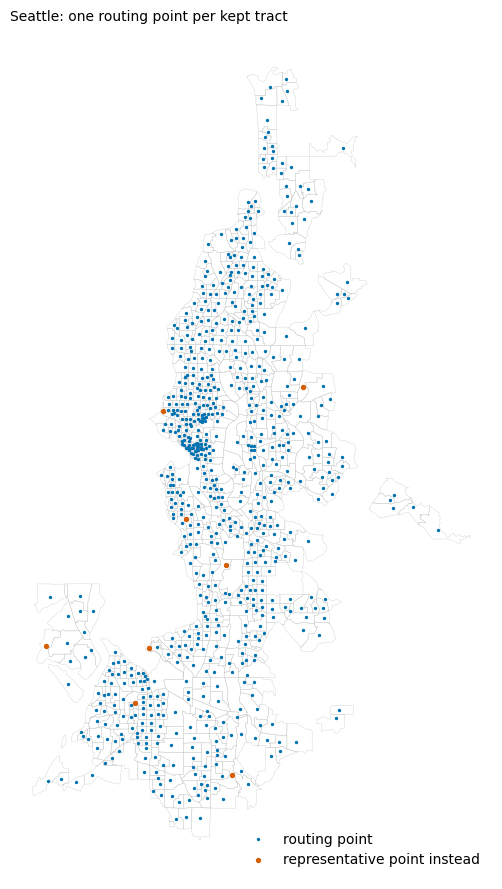

In [7]:
routing_points = gpd.GeoDataFrame({"id": points["tract"]}, geometry=points["point"].to_numpy(), crs="EPSG:4326")
routing_points.to_parquet(RESULTS / f"tract-points-{YEAR}.parquet", index=False)

figure, axis = plt.subplots(figsize=(11, 9))
points.plot(ax=axis, facecolor="none", edgecolor="#bbbbbb", linewidth=0.2)
routing_points.plot(ax=axis, color="#0072B2", markersize=2, label="routing point")
points.loc[points["method"] != "weighted mean of block points"].set_geometry("point").plot(ax=axis, color="#D55E00", markersize=8, label="representative point instead")
axis.legend(frameon=False, loc="lower right")
axis.set_aspect(1 / np.cos(np.radians(points["lat"].mean())))
axis.set_title(f"{CITY}: one routing point per kept tract", loc="left", fontsize=10)
axis.set_axis_off()
figure.tight_layout()


## 4. Street network

The router needs the streets. They come from OpenStreetMap, in the Geofabrik extract named in the
parameters, which the notebook downloads if it is not on disk yet. cafein reads the extract once, clipped
to the bounding box of the kept tracts, builds the walking, cycling and driving graphs, and saves the
result on scratch for every later step.


In [8]:
if not OSM_PBF.exists():
    OSM_PBF.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(OSM_URL, OSM_PBF)
print(OSM_PBF.name, f"{OSM_PBF.stat().st_size / 1e9:.2f} GB")

bounding_box = tuple(tracts.to_crs("EPSG:4326").total_bounds)
started = time.time()
if STREET_ARTIFACT.exists():
    streets = StreetNetwork.load(STREET_ARTIFACT)
    print("loaded", STREET_ARTIFACT)
else:
    streets = StreetNetwork.from_osm(OSM_PBF, modes=("walk", "bicycle", "car"), country=COUNTRY, bounding_box=bounding_box)
    streets.save(STREET_ARTIFACT)
    print("built and saved", STREET_ARTIFACT)
print(f"{time.time() - started:.0f} s; bounding box {np.round(bounding_box, 3)}; vertices {streets.vertex_count:,}, edges {streets.edge_count:,}")


washington-latest.osm.pbf 0.37 GB


loaded /scratch/project_2010423/carbon-advantage/commuting/seattle/seattle-streets.cafein
2 s; bounding box [-122.708   47.003 -121.692   48.212]; vertices 3,817,038, edges 4,182,110


## 5. Snapping

A route has to begin and end on a street, and the point of step 3 usually sits inside a
block, a few metres from one. So each point is moved to the closest piece of street. Two
rules keep that honest: the street must lie inside the tract itself, so the point does not
jump into the neighbouring tract, and it may be at most 1 km away, otherwise the tract is
left without a point and the table lists it. Every segment of the street network counts
as a street, whether or not cars may use it.

The table says how far the points moved and which tracts, if any, were left out. The map
colours each tract by that distance and shows, for the centre of Seattle, the points before
and after the move.


In [9]:
started = time.time()
edges = streets.streets_gdf[["geometry"]].to_crs(METRIC_CRS)
polygons = points[["tract", "geometry"]].to_crs(METRIC_CRS)
centres = gpd.GeoSeries(points["point"], crs="EPSG:4326").to_crs(METRIC_CRS)
print(f"{len(edges):,} edges in {METRIC_CRS}, {time.time() - started:.0f} s")

# Which edges touch which tract (an edge crossing a border appears in both tracts).
edges_in_tracts = gpd.sjoin(edges, polygons, how="inner", predicate="intersects")
print(f"{len(edges_in_tracts):,} edge-tract matches, {time.time() - started:.0f} s")

snapped = []
for (tract, polygon), centre in zip(polygons[["tract", "geometry"]].itertuples(index=False), centres):
    inside = edges_in_tracts.loc[edges_in_tracts["tract"] == tract, "geometry"]
    if len(inside) == 0:
        snapped.append({"tract": tract, "snap_distance_m": np.nan, "snapped": None})
        continue
    # Keep only the parts of the edges that lie inside the tract, then take the closest point.
    streets_inside = inside.intersection(polygon).union_all()
    point_on_street = nearest_points(centre, streets_inside)[1]
    snapped.append({"tract": tract, "snap_distance_m": centre.distance(point_on_street), "snapped": point_on_street})
snapped = pd.DataFrame(snapped)
points = points.drop(columns=[c for c in ["snap_distance_m", "snapped", "within_rule"] if c in points.columns]).merge(snapped, on="tract")
points["within_rule"] = points["snap_distance_m"] <= SNAP_DISTANCE_M
print(f"snapping done in {time.time() - started:.0f} s")

print(f"{len(points):,} tracts; {points['snap_distance_m'].isna().sum()} with no street inside at all; "
      f"{(~points['within_rule']).sum()} left without a point under the {SNAP_DISTANCE_M} m rule")
print("distance from the point to the snapped point (m):")
display(points["snap_distance_m"].describe(percentiles=[0.5, 0.9, 0.99]).round(0).to_frame().T)
print("tracts left without a routable point:")
points.loc[~points["within_rule"], ["tract", "NAMELSADCO", "land_km2", "workers_home", "workers_work", "snap_distance_m"]].round(0)


4,182,110 edges in EPSG:32610, 30 s


3,016,310 edge-tract matches, 34 s


snapping done in 112 s
791 tracts; 0 with no street inside at all; 0 left without a point under the 1000 m rule
distance from the point to the snapped point (m):


,count,mean,std,min,50%,90%,99%,max
snap_distance_m,791.0,21.0,28.0,0.0,14.0,45.0,132.0,315.0


tracts left without a routable point:


,tract,NAMELSADCO,land_km2,workers_home,workers_work,snap_distance_m


791 routing points saved; they carry 100.00% of the resident workers


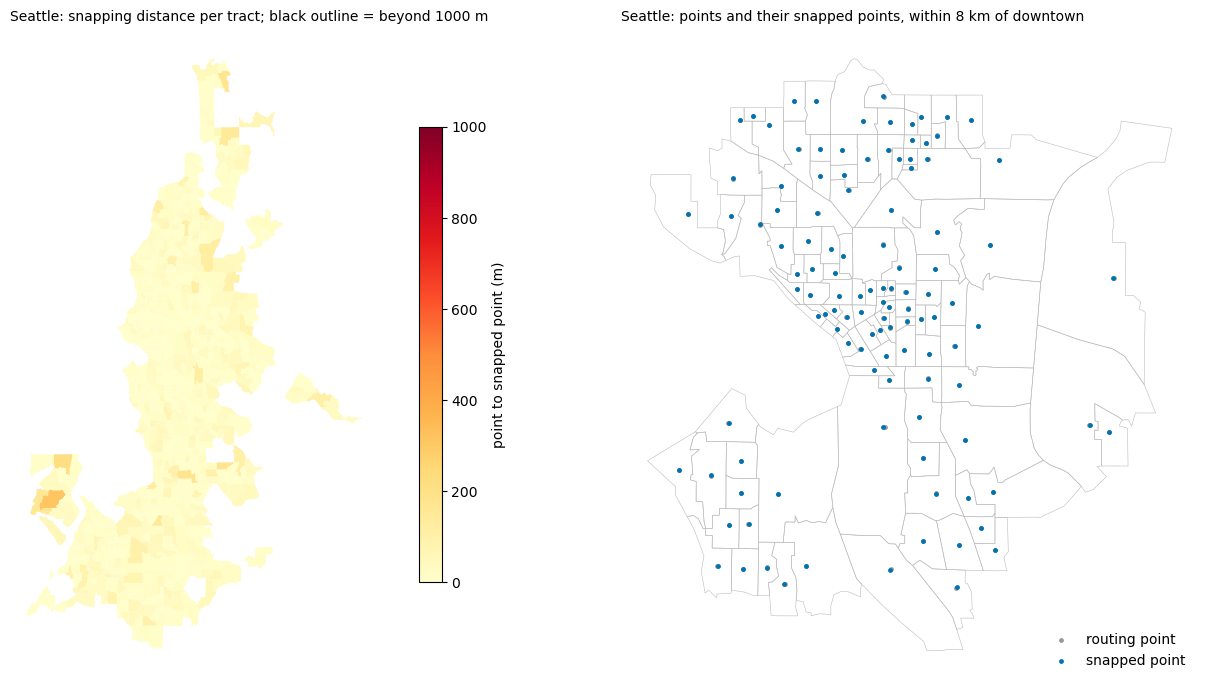

In [10]:
routing_points = gpd.GeoDataFrame(
    {"id": points.loc[points["within_rule"], "tract"].to_numpy()},
    geometry=points.loc[points["within_rule"], "snapped"].to_numpy(), crs=METRIC_CRS,
).to_crs("EPSG:4326")
routing_points.to_parquet(RESULTS / f"tract-points-snapped-{YEAR}.parquet", index=False)
print(f"{len(routing_points):,} routing points saved; they carry {points.loc[points['within_rule'], 'workers_home'].sum() / points['workers_home'].sum():.2%} of the resident workers")

figure, axes = plt.subplots(ncols=2, figsize=(16, 7))
points.plot(column="snap_distance_m", ax=axes[0], cmap="YlOrRd", vmin=0, vmax=SNAP_DISTANCE_M, edgecolor="none",
            legend=True, legend_kwds={"shrink": 0.7, "label": "point to snapped point (m)"},
            missing_kwds={"color": "#444444", "label": "no street inside"})
if (~points["within_rule"]).any():   # an empty frame cannot be drawn; in some metros every point snaps within the rule
    points.loc[~points["within_rule"]].plot(ax=axes[0], facecolor="none", edgecolor="black", linewidth=1.2)
axes[0].set_title(f"{CITY}: snapping distance per tract; black outline = beyond {SNAP_DISTANCE_M} m", loc="left", fontsize=10)

# The centre of Seattle: the tracts within 8 km of downtown.
downtown = gpd.GeoSeries([gpd.points_from_xy([-122.3321], [47.6062])[0]], crs="EPSG:4326").to_crs(METRIC_CRS).iloc[0]
central = points.loc[polygons.geometry.centroid.distance(downtown).to_numpy() < 8000]
central.plot(ax=axes[1], facecolor="none", edgecolor="#bbbbbb", linewidth=0.4)
gpd.GeoSeries(central["point"], crs="EPSG:4326").plot(ax=axes[1], color="#999999", markersize=6, label="routing point")
gpd.GeoSeries(central["snapped"], crs=METRIC_CRS).to_crs("EPSG:4326").plot(ax=axes[1], color="#0072B2", markersize=6, label="snapped point")
axes[1].legend(frameon=False, loc="lower right")
axes[1].set_title(f"{CITY}: points and their snapped points, within 8 km of downtown", loc="left", fontsize=10)
for axis in axes:
    axis.set_aspect(1 / np.cos(np.radians(points["lat"].mean())))
    axis.set_axis_off()
figure.tight_layout()


## 6. Street modes

Now the routing itself, for the modes that need only streets. cafein computes the travel
time from every routing point to every other one, four times: by car as if the roads were
empty (free-flow), by car with the delays at junctions of the morning rush added, by
bicycle, and by e-bike. The e-bike rides the same streets as the bicycle at 17.4 km/h on the flat against the
bicycle's 15.3, the mean trip speeds of pedelecs and conventional bicycles in Schleinitz et
al. (2017) and cafein's defaults, set as in Helsinki; there is no elevation model here, so
neither mode is slowed by slopes. Each result is a table of about two million point pairs, written to scratch in
pieces so that a later run can reuse it instead of recomputing.

Then the tract flows of step 2 are joined to those tables: every pair of tracts gets its
workers, the straight-line distance between its two points, and its four times in
minutes. Two things to know when reading the numbers: a worker whose home and work are in
the same tract gets zero minutes, because the point routes to itself, and cafein stops a
street route at 120 minutes, so a bicycle trip longer than that counts as not reached.


In [11]:
def matrix_complete(path):
    # True when a streamed matrix folder has every shard completed.
    manifest = Path(path) / "manifest.json"
    if not manifest.is_file():
        return False
    shards = json.loads(manifest.read_text())["shards"]
    return bool(shards) and all(shard["completed"] for shard in shards)


for mode in STREET_MODES:
    output = MATRICES / STREET_QUERIES[mode]["folder"]
    if matrix_complete(output):
        print(f"{mode:12} complete -> {output}")
        continue
    started = time.time()
    TravelTimeMatrix.to_parquet(streets, routing_points, routing_points, output=output, output_time_units="seconds",
                                resume=output.exists(), **STREET_QUERIES[mode]["query"])
    print(f"{mode:12} {time.time() - started:6.0f} s -> {output}")


car_freeflow complete -> /scratch/project_2010423/carbon-advantage/commuting/seattle/matrices/car
car          complete -> /scratch/project_2010423/carbon-advantage/commuting/seattle/matrices/car-rush
bicycle      complete -> /scratch/project_2010423/carbon-advantage/commuting/seattle/matrices/bicycle
e_bike       complete -> /scratch/project_2010423/carbon-advantage/commuting/seattle/matrices/e_bike


In [12]:
od_times = od.loc[od["from_id"].isin(routing_points["id"]) & od["to_id"].isin(routing_points["id"])].copy()
coordinates = routing_points.set_index("id").geometry
home_lon, home_lat = coordinates.x.loc[od_times["from_id"]].to_numpy(), coordinates.y.loc[od_times["from_id"]].to_numpy()
work_lon, work_lat = coordinates.x.loc[od_times["to_id"]].to_numpy(), coordinates.y.loc[od_times["to_id"]].to_numpy()
od_times["straight_km"] = np.hypot((work_lon - home_lon) * np.cos(np.radians(home_lat)) * 111.32, (work_lat - home_lat) * 110.57)

for mode in STREET_MODES:
    matrix = read_shards(MATRICES / STREET_QUERIES[mode]["folder"])[["from_id", "to_id", "travel_time"]].rename(columns={"travel_time": f"{mode}_min"})
    matrix[f"{mode}_min"] = matrix[f"{mode}_min"] / 60
    od_times = od_times.merge(matrix, on=["from_id", "to_id"], how="left")
od_times.to_parquet(MATRICES / f"tract-od-times-{YEAR}.parquet", index=False)
print(f"{len(od_times):,} tract pairs with a flow between routing points, {od_times['workers'].sum():,} workers")
od_times.head()


253,835 tract pairs with a flow between routing points, 1,531,980 workers


,from_id,to_id,workers,straight_km,car_freeflow_min,car_min,bicycle_min,e_bike_min
0,53033000101,53033000101,4,0.000000,0.000000,0.000000,0.000000,0.000000
1,53033000101,53033000102,12,0.796294,1.866667,6.100000,4.416667,3.900000
2,53033000101,53033000201,1,1.701520,4.550000,10.583333,9.033333,8.000000
3,53033000101,53033000202,1,0.752907,1.933333,4.333333,4.050000,3.566667
4,53033000101,53033000300,2,3.146457,5.116667,17.700000,15.100000,13.283333


In [13]:
def weighted_percentiles(values, weights, percentiles):
    order = np.argsort(values)
    cumulative = np.cumsum(weights[order]) / weights.sum()
    return [values[order][np.searchsorted(cumulative, p / 100)] for p in percentiles]


def weighted_median(values, weights):
    return weighted_percentiles(values, weights, [50])[0]


def mode_summary(table, modes):
    # Worker-weighted summary of the travel times of each mode, over the pairs it reaches.
    summary = {}
    for mode in modes:
        reached = table[f"{mode}_min"].notna()
        minutes = table.loc[reached, f"{mode}_min"].to_numpy()
        weights = table.loc[reached, "workers"].to_numpy()
        straight = table.loc[reached, "straight_km"].to_numpy()
        summary[mode] = {
            "share of workers reached": weights.sum() / table["workers"].sum(),
            "mean minutes, worker-weighted": np.average(minutes, weights=weights),
            "median minutes, worker-weighted": weighted_median(minutes, weights),
            "p90 minutes, worker-weighted": weighted_percentiles(minutes, weights, [90])[0],
            # Straight-line distance covered per hour, over the pairs between different tracts.
            "straight-line km per hour, between tracts": straight[minutes > 0].dot(weights[minutes > 0]) / (minutes[minutes > 0] / 60).dot(weights[minutes > 0]),
        }
    return pd.DataFrame(summary)


print("commutes between the kept tracts, by mode:")
mode_summary(od_times, STREET_MODES).round(2)


commutes between the kept tracts, by mode:


,car_freeflow,car,bicycle,e_bike
share of workers reached,0.99,0.99,0.76,0.81
"mean minutes, worker-weighted",18.96,37.22,55.29,52.62
"median minutes, worker-weighted",16.42,34.57,53.42,50.17
"p90 minutes, worker-weighted",35.83,62.92,101.23,98.37
"straight-line km per hour, between tracts",57.27,28.93,11.97,13.66


median minutes per home tract, across tracts:


,count,mean,std,min,25%,50%,75%,max
car_freeflow_median_min,791.0,17.0,5.9,0.0,13.3,16.9,20.3,39.6
car_median_min,791.0,35.7,10.9,0.0,28.7,35.0,42.2,73.8
bicycle_median_min,791.0,53.0,18.5,0.0,40.1,54.2,67.7,96.0
e_bike_median_min,791.0,49.9,17.9,0.0,37.2,50.9,63.3,104.5


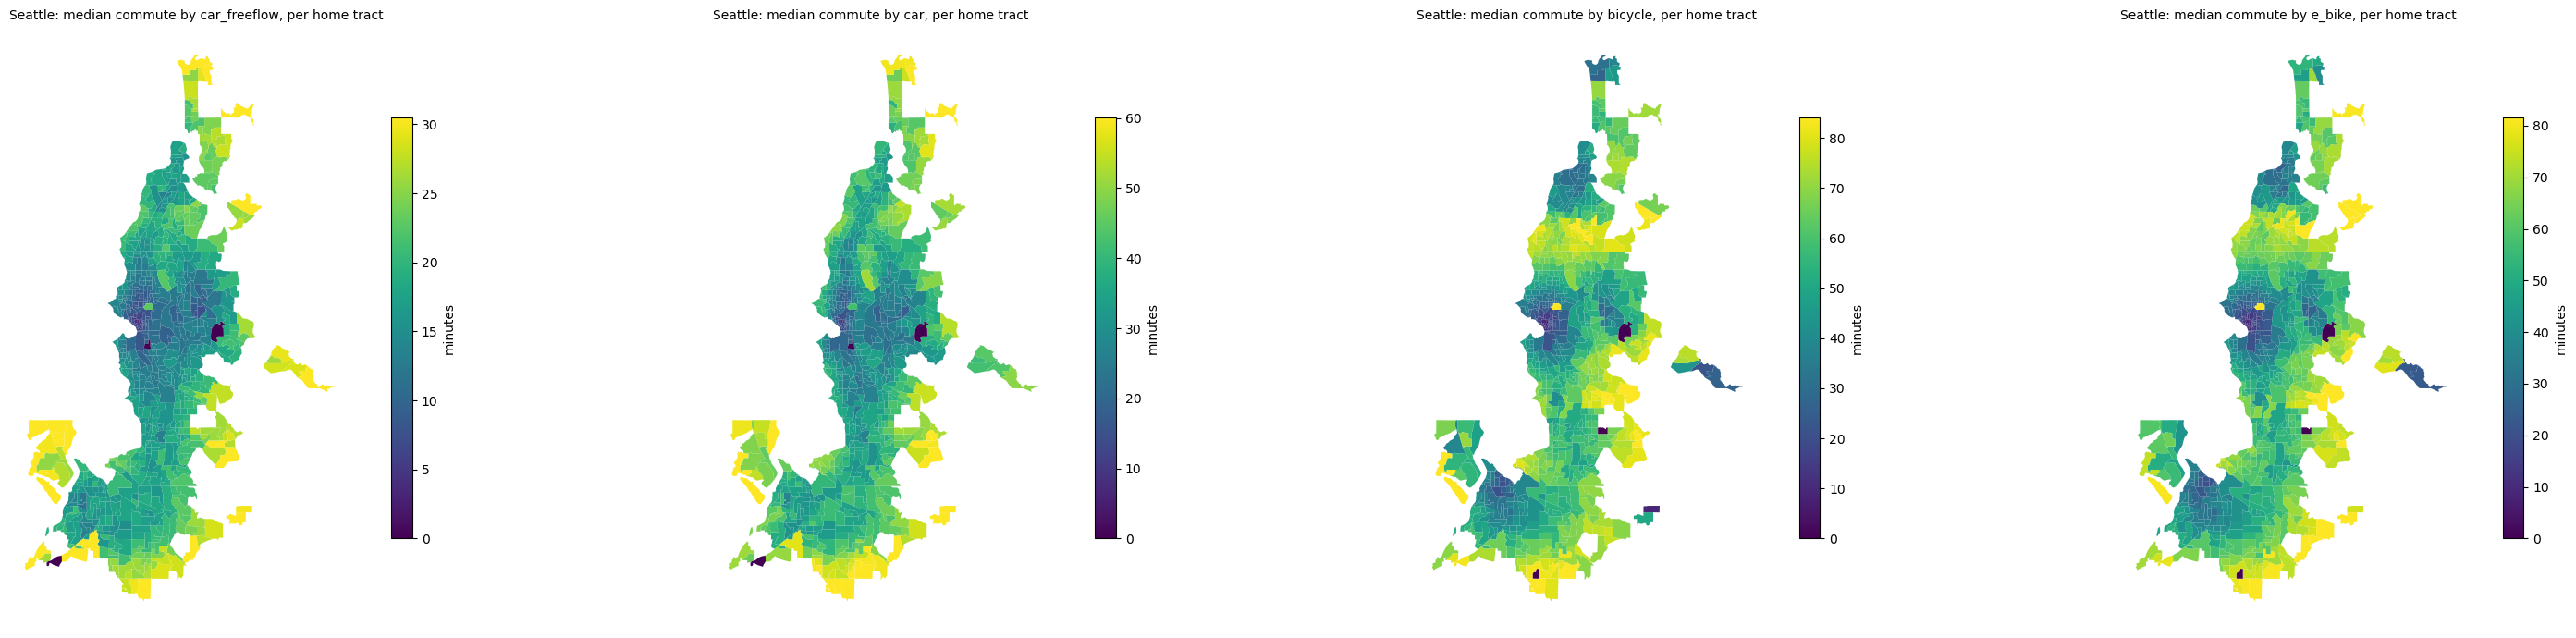

In [14]:
def median_by_home_tract(table, modes):
    # Worker-weighted median travel time of the residents of each home tract, per mode.
    per_tract = pd.DataFrame({"residents": table.groupby("from_id")["workers"].sum()})
    for mode in modes:
        column = f"{mode}_min"
        reached = table.loc[table[column].notna()]
        per_tract[f"{mode}_median_min"] = reached.groupby("from_id").apply(lambda rows: weighted_median(rows[column].to_numpy(), rows["workers"].to_numpy()), include_groups=False)
    return per_tract.rename_axis("tract").reset_index()


def map_medians(per_tract, modes):
    mapped = tracts[["tract", "geometry"]].merge(per_tract, on="tract", how="left")
    figure, axes = plt.subplots(ncols=len(modes), figsize=(8 * len(modes), 7))
    for axis, mode in zip(np.atleast_1d(axes), modes):
        column = f"{mode}_median_min"
        mapped.plot(column=column, ax=axis, cmap="viridis", vmin=0, vmax=np.nanpercentile(mapped[column], 98), edgecolor="none",
                    legend=True, legend_kwds={"shrink": 0.7, "label": "minutes"}, missing_kwds={"color": "#ececea"})
        axis.set_title(f"{CITY}: median commute by {mode}, per home tract", loc="left", fontsize=10)
        axis.set_aspect(1 / np.cos(np.radians(points["lat"].mean())))
        axis.set_axis_off()
    figure.tight_layout()


per_tract = median_by_home_tract(od_times, STREET_MODES)
per_tract.to_parquet(MATRICES / f"median-minutes-by-home-tract-{YEAR}.parquet", index=False)
map_medians(per_tract, STREET_MODES)
print("median minutes per home tract, across tracts:")
per_tract[[f"{mode}_median_min" for mode in STREET_MODES]].describe(percentiles=[0.25, 0.5, 0.75]).round(1).T


## 7. Timetables

The transit feeds come through transitio: it lists the operators whose feeds serve the polygon of the
kept tracts on the chosen Tuesday, downloads their files, checks them, repairs what it can and drops the
ones with no service on the date. The table below says what Seattle gets: which operators, how many
routes, trips and stops each, and what the validator found.


In [15]:
started = time.time()
area = tracts.to_crs("EPSG:4326").union_all()
fetched = transitio.fetch(aoi=area, when=pd.Timestamp(DEPARTURE).date(), osm=False, directory=GTFS_DIR)
print(f"transitio fetch done in {time.time() - started:.0f} s")
GTFS_FILES = [Path(str(feed)) for feed in fetched.feeds]
print(f"{len(GTFS_FILES)} feeds delivered, {sum(path.stat().st_size for path in GTFS_FILES) / 1e6:.0f} MB")
print("skipped:", fetched.skipped)
for report in fetched.reports:
    print("report:", str(report)[:400])


Fetching 34 feeds for the area


  0%|          | 0.00/7.82k [00:00<?, ?B/s]

[1/34] f-psesd~wa~us~flex: skipped (no trip stops in the area)


[2/34] f-seattlemonorail~wa~us: cached copy reused


[3/34] f-seatac~ep: cached copy reused


[4/34] f-solidground~wa~us: cached copy reused


... (39 outputs left out)

Comparing trips across 23 feeds


/tmp/marinflo/3375741/ipykernel_467702/2904956454.py:3: UserWarning: trips left out as near repeats took departures at stops the trips they repeat do not serve: f-mdb-1080: 29 at 2 stops (3473, 3194); duplicate_trips="exact" keeps near repeats
  fetched = transitio.fetch(aoi=area, when=pd.Timestamp(DEPARTURE).date(), osm=False, directory=GTFS_DIR)
[24/34] f-c23-metrokingcounty: left out (every trip on 2026-11-10 repeats a trip of f-mdb-1330)


Done in 1 min 0 s: 22 feeds delivered, 12 skipped, 2.0 MB downloaded


transitio fetch done in 60 s
22 feeds delivered, 49 MB
skipped: [('f-psesd~wa~us~flex', 'no trip stops in the area'), ('f-c28-victoriaclipper', 'no trip stops in the area'), ('f-mdb-270', 'service ended 2024-07-01; unchanged since indexed'), ('f-c23n-microsoftshuttles', 'service ended 2020-12-31; unchanged since indexed'), ('f-homage~wa~us', 'service ended 2025-06-30; unchanged since indexed'), ('f-mdb-2311', 'service ended 2025-06-30; unchanged since indexed'), ('f-soundgenerations~wa~us~flex', 'no trip stops in the area'), ('f-mdb-282', 'no trip stops in the area'), ('f-c23-metrokingcounty', 'every trip on 2026-11-10 repeats a trip of f-mdb-1330'), ('f-skagit~wa~us', 'service starts 2026-11-14, after 2026-11-10'), ('f-c28-washingtonstateferries', 'service starts 2026-11-23, after 2026-11-10'), ('f-northwestern~stagelines~or', 'service starts 2026-11-23, after 2026-11-10')]
report: {'summary': {'validator': {'name': 'transitio', 'version': '0.28.0'}, 'generatedAt': '2026-11-24T11:06:0

**Units of the shape distances.** cafein 0.31 decides per trip whether a feed's `shape_dist_traveled` is in metres or kilometres and takes feet for metres, which makes every ridden distance and the grams computed from it 3.28 times too large for operators that publish feet (CTA; Sound Transit, King County Metro and Intercity Transit). The script `jobs/fix-gtfs-shape-dist-units.py` decides the unit once per feed from its shapes and rewrites feet feeds in metres, in place; it runs here after every fetch, before the network is built, and leaves metre feeds alone.

In [16]:
import subprocess
import sys

fix = subprocess.run([sys.executable, "../../jobs/fix-gtfs-shape-dist-units.py", str(GTFS_DIR), "--apply"], capture_output=True, text=True)
print(fix.stdout + fix.stderr)

seattle    f-9-amtrak~amtrakcalifornia~amtrakcharteredvehicle.z none         
seattle    f-9-flixbus.zip                                      none         
seattle    f-c2-appleline~goldline~dungenessline~grapeline.zip  none         
seattle    f-c22-piercetransit~soundtransit.zip                 metres       
seattle    f-c22e-intercitytransit.zip                          feet         converted to metres, now metres
seattle    f-c22y-kitsaptransit.zip                             metres       
seattle    f-c23-soundtransit.zip                               feet         converted to metres, now metres
seattle    f-c28-islandtransit.zip                              metres       
seattle    f-c29-communitytransit.zip                           metres       
seattle    f-c290-everetttransit.zip                            none         
seattle    f-mdb-1080.zip                                       feet         converted to metres, now metres
seattle    f-mdb-1330.zip                        

In [17]:
ROUTE_TYPE_NAMES = {0: "tram", 1: "metro", 2: "rail", 3: "bus", 4: "ferry", 5: "cable tram", 6: "aerial", 7: "funicular", 11: "trolleybus", 12: "monorail"}


def gtfs_summary(path):
    # Counts and dates of one GTFS zip, without unpacking it to disk.
    with zipfile.ZipFile(path) as archive:
        names = set(archive.namelist())
        agency = pd.read_csv(archive.open("agency.txt"))
        routes = pd.read_csv(archive.open("routes.txt"))
        stops = pd.read_csv(archive.open("stops.txt"), usecols=["stop_id"])
        trips = pd.read_csv(archive.open("trips.txt"), usecols=["trip_id"])
        dates = []
        if "calendar.txt" in names:
            calendar = pd.read_csv(archive.open("calendar.txt"), dtype=str)
            dates += [calendar["start_date"].min(), calendar["end_date"].max()]
        if "calendar_dates.txt" in names:
            exceptions = pd.read_csv(archive.open("calendar_dates.txt"), dtype=str)
            dates += [exceptions["date"].min(), exceptions["date"].max()]
    by_type = routes["route_type"].map(lambda t: ROUTE_TYPE_NAMES.get(int(t), f"type {t}")).value_counts()
    return {"file": Path(path).name, "agencies": len(agency), "routes": len(routes), "stops": len(stops), "trips": len(trips),
            "first_date": min(dates) if dates else None, "last_date": max(dates) if dates else None, **{f"routes_{k}": v for k, v in by_type.items()}}


feeds = pd.DataFrame([gtfs_summary(path) for path in GTFS_FILES]).set_index("file").sort_values("trips", ascending=False)
feeds[[c for c in feeds.columns if c.startswith("routes_")]] = feeds[[c for c in feeds.columns if c.startswith("routes_")]].fillna(0).astype(int)
print(f"{len(feeds)} feeds, {feeds['trips'].sum():,} trips, {feeds['stops'].sum():,} stops")
feeds


22 feeds, 154,986 trips, 21,306 stops


,agencies,routes,stops,trips,first_date,last_date,routes_monorail,routes_bus,routes_ferry,routes_tram,routes_rail
file,,,,,,,,,,,
f-mdb-1080.zip,11,230,10179,65329,20250902,20270530,0,202,19,5,4
f-mdb-1330.zip,3,140,6242,31404,20260829,20271231,0,136,2,2,0
f-c23-soundtransit.zip,1,6,189,15905,20261003,20270328,0,1,0,3,2
f-c29-communitytransit.zip,2,40,1768,14810,20261110,20270326,0,40,0,0,0
f-mdb-1331.zip,1,12,10,14302,20261104,20261226,0,0,12,0,0
f-c22-piercetransit~soundtransit.zip,2,41,1974,8912,20260830,20261212,0,41,0,0,0
f-seattlemonorail~wa~us.zip,1,1,2,2010,20250902,20270530,1,0,0,0,0
f-c290-everetttransit.zip,1,10,496,1098,20260906,20261213,0,10,0,0,0
f-c22e-intercitytransit.zip,1,2,34,418,20260927,20270102,0,2,0,0,0


## 8. Transit

cafein now combines the eleven timetables with the street map into one transit network:
the stops are linked to the streets so that a trip can walk to a stop, ride, change and
walk again. Built once and saved on scratch; later runs load it. Then it computes the
transit travel time from every routing point to every other one for a departure at 08:30
on the chosen Tuesday, with the walk to the first stop and from the last stop capped at 30 minutes, as in 05.9 and 05.10, and cafein's defaults for the transfers,
streamed to scratch like the street matrices.

The transit times join the table of step 6, so each pair of tracts now carries four times.
The summary and the maps are repeated for all modes.


In [18]:
started = time.time()
if TRANSIT_ARTIFACT.exists():
    transit_network = TransportNetwork.load(TRANSIT_ARTIFACT)
    print("loaded", TRANSIT_ARTIFACT)
else:
    transit_network = TransportNetwork.from_gtfs(GTFS_FILES, osm_pbf=OSM_PBF, street_modes=("walk", "bicycle", "car"),
                                                 country=COUNTRY, bounding_box=bounding_box)
    transit_network.save(TRANSIT_ARTIFACT)
    print("built and saved", TRANSIT_ARTIFACT)
print(f"{time.time() - started:.0f} s; {transit_network.stop_count:,} stops, {transit_network.trip_count:,} trips")


building the transit core from GTFS:   0%|          | 0/3 [00:02<?, ?it/s]

/tmp/marinflo/3375741/ipykernel_467702/2375934466.py:6: UserWarning: /scratch/project_2010423/data/gtfs/seattle/f-muckleshoot~wa~us.zip: frequencies.txt, trip TL-421: row 05:30:00–07:30:00 every 3247 s: the template's first stop has no time
  transit_network = TransportNetwork.from_gtfs(GTFS_FILES, osm_pbf=OSM_PBF, street_modes=("walk", "bicycle", "car"),
/tmp/marinflo/3375741/ipykernel_467702/2375934466.py:6: UserWarning: /scratch/project_2010423/data/gtfs/seattle/f-muckleshoot~wa~us.zip: frequencies.txt, trip TL-421: omitted: none of its frequencies.txt rows could be expanded
  transit_network = TransportNetwork.from_gtfs(GTFS_FILES, osm_pbf=OSM_PBF, street_modes=("walk", "bicycle", "car"),
/tmp/marinflo/3375741/ipykernel_467702/2375934466.py:6: UserWarning: interpolated blank stop times on 49 trip(s)
  transit_network = TransportNetwork.from_gtfs(GTFS_FILES, osm_pbf=OSM_PBF, street_modes=("walk", "bicycle", "car"),


reading the OSM walking network:  14%|#3        | 13.8/100 [00:02<00:12,  6.89it/s]

/tmp/marinflo/3375741/ipykernel_467702/2375934466.py:6: UserWarning: 413 stop(s) are farther than 1600.0 m from the walking network and get no footpaths
  transit_network = TransportNetwork.from_gtfs(GTFS_FILES, osm_pbf=OSM_PBF, street_modes=("walk", "bicycle", "car"),


reading the OSM street network:  16%|#5        | 15.9/100 [00:02<00:10,  7.94it/s]

saving the network:  50%|#####     | 1/2 [00:02<00:02,  2.00s/it]

built and saved /scratch/project_2010423/carbon-advantage/commuting/seattle/seattle-transit.cafein
166 s; 21,306 stops, 155,446 trips


In [19]:
output = MATRICES / f"transit-walk{ACCESS_EGRESS_WALK_MIN}"
if matrix_complete(output):
    print(f"transit      complete -> {output}")
else:
    started = time.time()
    TravelTimeMatrix.to_parquet(transit_network, routing_points, routing_points, output=output, departure=DEPARTURE, max_walking_time=ACCESS_EGRESS_WALK_MIN,
                                output_time_units="seconds", resume=output.exists())
    print(f"transit      {time.time() - started:6.0f} s -> {output}")

matrix = read_shards(output)[["from_id", "to_id", "travel_time"]].rename(columns={"travel_time": "transit_min"})
matrix["transit_min"] = matrix["transit_min"] / 60
od_times = od_times.drop(columns=[c for c in ["transit_min"] if c in od_times.columns]).merge(matrix, on=["from_id", "to_id"], how="left")
od_times.to_parquet(MATRICES / f"tract-od-times-{YEAR}.parquet", index=False)

print("commutes between the kept tracts, by mode:")
mode_summary(od_times, MODES).round(2)


transit      complete -> /scratch/project_2010423/carbon-advantage/commuting/seattle/matrices/transit-walk30


commutes between the kept tracts, by mode:


,car_freeflow,car,bicycle,e_bike,transit
share of workers reached,0.99,0.99,0.76,0.81,0.85
"mean minutes, worker-weighted",18.96,37.22,55.29,52.62,86.38
"median minutes, worker-weighted",16.42,34.57,53.42,50.17,77.68
"p90 minutes, worker-weighted",35.83,62.92,101.23,98.37,146.10
"straight-line km per hour, between tracts",57.27,28.93,11.97,13.66,11.82


median minutes per home tract, across tracts:


,count,mean,std,min,25%,50%,75%,max
car_freeflow_median_min,791.0,17.0,5.9,0.0,13.3,16.9,20.3,39.6
car_median_min,791.0,35.7,10.9,0.0,28.7,35.0,42.2,73.8
bicycle_median_min,791.0,53.0,18.5,0.0,40.1,54.2,67.7,96.0
e_bike_median_min,791.0,49.9,17.9,0.0,37.2,50.9,63.3,104.5
transit_median_min,791.0,73.7,49.3,0.0,49.4,74.0,98.5,599.9


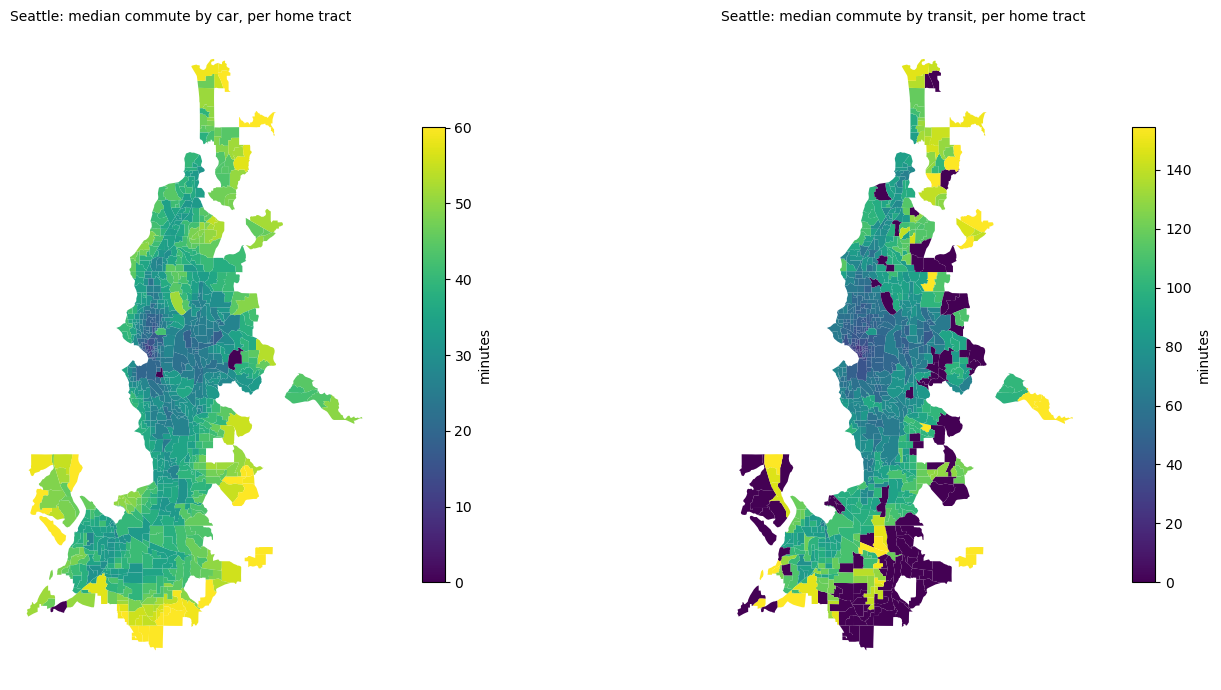

In [20]:
per_tract = median_by_home_tract(od_times, MODES)
per_tract.to_parquet(MATRICES / f"median-minutes-by-home-tract-{YEAR}.parquet", index=False)
map_medians(per_tract, ["car", "transit"])
print("median minutes per home tract, across tracts:")
per_tract[[f"{mode}_median_min" for mode in MODES]].describe(percentiles=[0.25, 0.5, 0.75]).round(1).T


## 9. Checking the feeds

What the build of step 8 warned about, and what it means in practice: the validation report of each
feed as transitio produced it; per feed, how many trips the file holds and how many cafein kept, and for
the feed losing most, which routes and service days those trips belong to and whether they run on our
Tuesday; and the stops without a footpath, which can be reached by riding but not on foot.


In [21]:
def error_notices(report):
    # The error-level notices of one transitio report, as (code, count, sample) rows.
    notices = report.get("notices", []) if isinstance(report, dict) else getattr(report, "notices", [])
    rows = []
    for notice in notices:
        if str(notice.get("severity", "")).upper() != "ERROR":
            continue
        sample = notice.get("sampleNotices", [None])
        rows.append((notice.get("code"), notice.get("totalNotices", len(sample)), str(sample[0] if sample else "")[:120]))
    return rows


feed_ids = list(fetched.paths)
for feed_id, report in zip(feed_ids, fetched.reports):
    summary = report.get("summary", {}) if isinstance(report, dict) else {}
    counts = summary.get("counts", {})
    print(f"{feed_id}: {counts.get('errors', '?')} errors, {counts.get('warnings', '?')} warnings")
    for code, count, sample in error_notices(report):
        print(f"    {code} x{count}: {sample}")


f-seattlemonorail~wa~us: 0 errors, 13 warnings
f-seatac~ep: 15 errors, 1 warnings
    block_trips_with_overlapping_stop_times x15: {'blockId': 'Active Times', 'csvRowNumber': 27, 'tripIdA': 'TL-4', 'tripIdB': 'TL-5'}
f-solidground~wa~us: 0 errors, 0 warnings
f-piercecountyferries~wa~us: 0 errors, 11 warnings
f-mdb-2326: 0 errors, 0 warnings
f-muckleshoot~wa~us: 31 errors, 4 warnings
    block_trips_with_overlapping_stop_times x27: {'blockId': 'Reservation Route', 'csvRowNumber': 94, 'tripIdA': 'TL-369', 'tripIdB': 'TL-370'}
    missing_trip_edge x4: {'csvRowNumber': 1336, 'specifiedField': 'arrival_time', 'tripId': 'TL-421'}
f-c290-everetttransit: 0 errors, 0 warnings
f-snowgoosetransit~wa~us: 0 errors, 0 warnings
f-snoqualmie~wa~us: 0 errors, 0 warnings
f-c22e-intercitytransit: 0 errors, 1 warnings
f-c22y-kitsaptransit: 0 errors, 2 warnings
f-c23-soundtransit: 4 errors, 51 warnings
    missing_required_field x4: {'csvRowNumber': 2, 'fieldName': 'transfer_type', 'fieldValue': '', 'file

In [22]:
kept = pd.DataFrame(transit_network.trips, columns=["trip_id", "route_id"])
kept_ids = set(kept["trip_id"])
rows = []
missing_by_feed = {}
for index, path in enumerate(GTFS_FILES):
    with zipfile.ZipFile(path) as archive:
        trips = pd.read_csv(archive.open("trips.txt"), dtype=str)
    # cafein qualifies ids as <feed_index>:<id> when feeds collide; try both spellings.
    in_network = trips["trip_id"].isin(kept_ids) | (f"{index}:" + trips["trip_id"]).isin(kept_ids)
    rows.append({"feed": path.name, "trips in file": len(trips), "trips kept": int(in_network.sum()), "trips left out": int((~in_network).sum())})
    missing_by_feed[path] = trips.loc[~in_network]
trip_counts = pd.DataFrame(rows).set_index("feed").sort_values("trips left out", ascending=False)
print(f"{trip_counts['trips in file'].sum():,} trips in the files, {trip_counts['trips kept'].sum():,} kept by cafein ({transit_network.trip_count:,} routable)")
display(trip_counts)

worst = trip_counts.index[0]
worst_path = next(path for path in GTFS_FILES if path.name == worst)
missing = missing_by_feed[worst_path]
with zipfile.ZipFile(worst_path) as archive:
    names = set(archive.namelist())
    routes = pd.read_csv(archive.open("routes.txt"), dtype=str)
    stop_times = pd.read_csv(archive.open("stop_times.txt"), dtype=str)
    calendar = pd.read_csv(archive.open("calendar.txt"), dtype=str) if "calendar.txt" in names else pd.DataFrame()
    exceptions = pd.read_csv(archive.open("calendar_dates.txt"), dtype=str) if "calendar_dates.txt" in names else pd.DataFrame()
day = pd.Timestamp(DEPARTURE)
weekday = day.day_name().lower()
running = set()
if len(calendar):
    active = calendar[(calendar[weekday] == "1") & (calendar["start_date"] <= day.strftime("%Y%m%d")) & (calendar["end_date"] >= day.strftime("%Y%m%d"))]
    running |= set(active["service_id"])
if len(exceptions):
    on_day = exceptions[exceptions["date"] == day.strftime("%Y%m%d")]
    running |= set(on_day.loc[on_day["exception_type"] == "1", "service_id"])
    running -= set(on_day.loc[on_day["exception_type"] == "2", "service_id"])
missing = missing.merge(routes[["route_id", "route_short_name", "route_long_name"]], on="route_id", how="left")
missing["runs on the departure day"] = missing["service_id"].isin(running)
stops_per_trip = stop_times.groupby("trip_id").size()
missing["stop_times"] = missing["trip_id"].map(stops_per_trip).fillna(0).astype(int)
print(f"{worst}: {len(missing):,} trips left out, {missing['runs on the departure day'].sum():,} of them scheduled on {day.date()}; "
      f"stop times per left-out trip: min {missing['stop_times'].min()}, median {missing['stop_times'].median():.0f}")
print("left-out trips by route and service:")
missing.groupby(["route_short_name", "route_long_name", "service_id", "runs on the departure day"]).size().rename("trips").sort_values(ascending=False).head(25).to_frame()


154,986 trips in the files, 154,985 kept by cafein (155,446 routable)


,trips in file,trips kept,trips left out
feed,,,
f-muckleshoot~wa~us.zip,30,29,1
f-seattlemonorail~wa~us.zip,2010,2010,0
f-seatac~ep.zip,6,6,0
f-solidground~wa~us.zip,18,18,0
f-piercecountyferries~wa~us.zip,181,181,0
f-mdb-2326.zip,50,50,0
f-c290-everetttransit.zip,1098,1098,0
f-snowgoosetransit~wa~us.zip,7,7,0
f-snoqualmie~wa~us.zip,36,36,0


f-muckleshoot~wa~us.zip: 1 trips left out, 1 of them scheduled on 2026-11-10; stop times per left-out trip: min 41, median 41
left-out trips by route and service:


,,,,trips
route_short_name,route_long_name,service_id,runs on the departure day,


413 of 21,306 stops have no footpath
their names, most common first:


,stops
name,
Hwy 530 & 171st Ave NE,8
Hwy 530 & Ramstad Rd,6
Mountain Loop Hwy & Alvord St,4
Mountain Loop Hwy & Seeman St,4
Hwy 530 & C-Post Rd,4
Hwy 530 & 411th Ave NE,4
Hwy 530 & 294th St NE,4
72nd Ave NW & 265th St NW,4
Hwy 530 & Squire Creek Park Rd,4


0 of the 413 stops without a footpath lie inside the area; the rest are intercity stops outside it


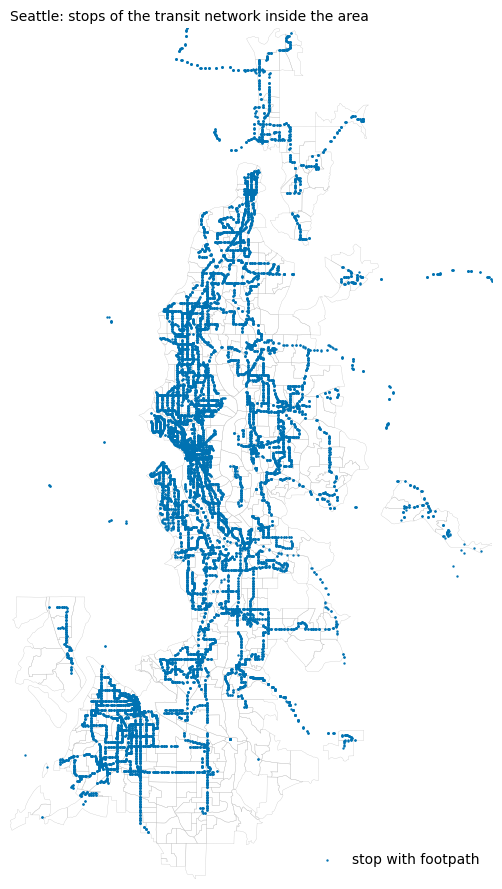

In [23]:
stops_all = transit_network.stops_gdf
with_footpath = set(transit_network.connectors_gdf["id"])
orphans = stops_all.loc[~stops_all["id"].isin(with_footpath)].copy()
print(f"{len(orphans):,} of {len(stops_all):,} stops have no footpath")
print("their names, most common first:")
display(orphans["name"].value_counts().head(10).to_frame("stops"))

# The feeds of Amtrak and Flixbus carry stops across the southern United States, so the
# view is clipped to the area; the stops outside it are counted instead of drawn.
west, south, east, north = tracts.to_crs("EPSG:4326").total_bounds
in_view = orphans.cx[west:east, south:north]
print(f"{len(in_view)} of the {len(orphans)} stops without a footpath lie inside the area; the rest are intercity stops outside it")

figure, axis = plt.subplots(figsize=(10, 9))
tracts.to_crs("EPSG:4326").plot(ax=axis, facecolor="none", edgecolor="#bbbbbb", linewidth=0.2)
stops_all.plot(ax=axis, color="#0072B2", markersize=0.5, label="stop with footpath")
if len(in_view):
    in_view.plot(ax=axis, color="#D55E00", markersize=20, label="stop without footpath")
axis.set_xlim(west, east)
axis.set_ylim(south, north)
axis.legend(frameon=False, loc="lower right")
axis.set_aspect(1 / np.cos(np.radians(points["lat"].mean())))
axis.set_title(f"{CITY}: stops of the transit network inside the area", loc="left", fontsize=10)
axis.set_axis_off()
figure.tight_layout()
